# Prediction intervals with the quantile loss

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

When we train a gradient boosting machine with the squared error, it predicts the mean rent of an apartment, but it doesn't tell us how far the real rent could be from that value. With the quantile loss, the model predicts a quantile of the rent instead of the mean. So if we train one model for the 5th percentile and another one for the 95th percentile, we obtain an interval that should contain the real rent of 90% of the apartments.

In this notebook, we train three gradient boosting machines, for the 5th, 50th and 95th percentiles, and we check whether the intervals contain the real rent as often as they should.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")

# the trees from Scikit-learn take numbers, so we replace the categories by integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

# GradientBoostingRegressor does not take missing values).
# For now, we replace NaN by a value outside the distribution.
df = df.fillna(-1)

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,1,1.0,1.0,0,1,0,1191.0,800.0,101,10,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,1,2.0,4.0,0,2,0,1450.0,1880.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,1,2.0,3.0,0,2,0,1395.0,1661.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,1,2.0,3.0,0,2,0,1255.0,1400.0,1955,9,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,1,2.0,2.0,0,2,0,1693.0,1346.0,101,10,...,0,0,0,0,0,1,0,0,0,0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

### Train one model per quantile

With `loss="quantile"`, the parameter `alpha` is the quantile that the model predicts. We train one model for each of the 5th, 50th and 95th percentiles. The 50th percentile is the median, which is the same as training the model with the absolute error.

We don't want to tune the number of trees for each model, so we set a large number of trees and let the model stop on its own with `n_iter_no_change`. The model separates 10% of the train set for validation, and it stops adding trees when the quantile loss in the validation set does not improve for 5 trees in a row. We use trees of depth 5, because deeper trees worked better in the regression notebook.

In [4]:
quantiles = [0.05, 0.5, 0.95]

models = {}
for quantile in quantiles:
    model = GradientBoostingRegressor(
        loss="quantile",
        alpha=quantile,
        n_estimators=2000,
        max_depth=5,
        n_iter_no_change=5,
        validation_fraction=0.1,
        random_state=0,
    )
    model.fit(X_train, y_train)
    models[quantile] = model

    print(f"quantile {quantile}: {model.n_estimators_} trees")

quantile 0.05: 364 trees
quantile 0.5: 449 trees
quantile 0.95: 371 trees


In [5]:
predictions = pd.DataFrame({
    "lower": models[0.05].predict(X_test),
    "median": models[0.5].predict(X_test),
    "upper": models[0.95].predict(X_test),
    "real rent": y_test.values,
}, index=y_test.index)

predictions.head(10).round(0)

,lower,median,upper,real rent
time,,,,
2019-02-22 05:45:51,906.0,1235.0,1605.0,1599.0
2018-12-08 03:37:23,890.0,1070.0,1439.0,950.0
2019-02-22 07:23:26,639.0,923.0,1173.0,730.0
2019-02-22 10:17:36,1376.0,2019.0,2676.0,2013.0
2019-02-22 10:15:03,857.0,1029.0,1311.0,900.0
2019-09-17 20:29:51,1100.0,1675.0,2301.0,1785.0
2019-09-18 00:48:35,550.0,874.0,1220.0,850.0
2019-02-22 06:02:08,947.0,1417.0,2193.0,1729.0
2018-12-08 16:31:34,854.0,1259.0,1910.0,1889.0


Each apartment gets three predictions: the lower and upper limits of the interval, and the median, which is our best guess of the rent. For all of these 10 apartments, the real rent falls inside the interval.

### Does each model predict its quantile?

If the model of the 5th percentile works, the real rent should be below its prediction for 5% of the apartments, and the same goes for the other quantiles.

In [6]:
for quantile, column in zip(quantiles, ["lower", "median", "upper"]):
    below = (predictions["real rent"] < predictions[column]).mean()
    print(f"quantile {quantile}: the real rent is below the prediction for {below:.1%} of the apartments")

quantile 0.05: the real rent is below the prediction for 5.9% of the apartments
quantile 0.5: the real rent is below the prediction for 50.3% of the apartments
quantile 0.95: the real rent is below the prediction for 94.2% of the apartments


In [7]:
# the fraction of apartments whose real rent is inside the interval
inside = predictions["real rent"].between(predictions["lower"], predictions["upper"])

print(f"coverage of the interval: {inside.mean():.1%}")

coverage of the interval: 88.3%


The three models are close to their targets. The interval contains the real rent of 88% of the apartments, a bit less than the 90% that we aimed for.

### The intervals of some apartments

We plot the interval of 50 random apartments from the test set, sorted by the predicted median. The red dots are the apartments whose real rent falls outside the interval.

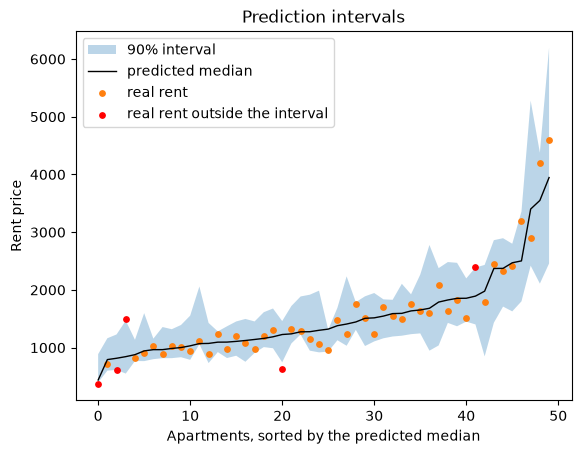

In [8]:
sample = predictions.sample(50, random_state=1).sort_values("median")
x = np.arange(len(sample))
outside = ~sample["real rent"].between(sample["lower"], sample["upper"])

plt.fill_between(x, sample["lower"], sample["upper"], alpha=0.3, label="90% interval")
plt.plot(x, sample["median"], color="black", linewidth=1, label="predicted median")
plt.scatter(x[~outside], sample.loc[~outside, "real rent"], s=15, label="real rent")
plt.scatter(x[outside], sample.loc[outside, "real rent"], s=15, color="red", label="real rent outside the interval")
plt.xlabel("Apartments, sorted by the predicted median")
plt.ylabel("Rent price")
plt.title("Prediction intervals")
plt.legend()
plt.show()

Most of the real rents fall inside the shaded area, and only a few fall outside, which is what we expect from an interval that should miss 1 in 10 apartments. Notice also that the width of the interval changes from one apartment to the next, and that it grows with the predicted rent.

### Each apartment gets its own interval

If we only had a model of the mean, we could add and subtract the same amount to every prediction, and every apartment would get an interval of the same width. With the quantile loss, the width of the interval depends on the apartment. Let's see how the width changes with the predicted rent.

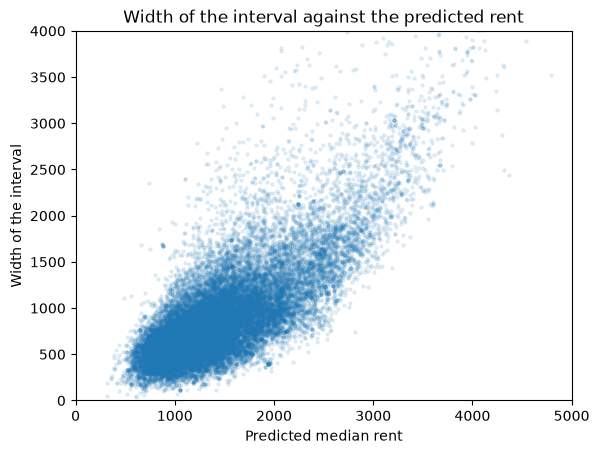

In [9]:
predictions["width"] = predictions["upper"] - predictions["lower"]

# We zoom into the most common prices, because a few apartments cost more than 30000
plt.scatter(predictions["median"], predictions["width"], alpha=0.1, s=5)
plt.xlim(0, 5000)
plt.ylim(0, 4000)
plt.xlabel("Predicted median rent")
plt.ylabel("Width of the interval")
plt.title("Width of the interval against the predicted rent")
plt.show()

In [10]:
# we sort the apartments into 5 groups of the same size by their predicted median
groups = pd.qcut(predictions["median"], 5)

predictions.assign(inside=inside).groupby(groups, observed=True).agg(
    coverage=("inside", "mean"),
    median_width=("width", "median"),
).round(2)

,coverage,median_width
median,,
"(317.39500000000004, 997.334]",0.88,539.17
"(997.334, 1221.825]",0.87,643.75
"(1221.825, 1468.913]",0.88,748.93
"(1468.913, 1868.837]",0.89,923.59
"(1868.837, 20191.641]",0.90,1434.89


The more expensive the apartment, the wider the interval: the median width goes from about 540 dollars for the cheapest apartments to about 1430 dollars for the most expensive ones. And yet, the coverage stays close to 90% in all the groups.

An interval of the same width for every apartment would be too wide for the cheap apartments and too narrow for the expensive ones. With the quantile loss, the model learns how uncertain the rent of each apartment is.

### Crossing quantiles

The three models are trained independently, so nothing forces the prediction of the 5th percentile to be smaller than the median, or the median to be smaller than the 95th percentile.

In [11]:
crossing = (predictions["lower"] > predictions["median"]) | (predictions["median"] > predictions["upper"])

print(f"apartments with crossing quantiles: {crossing.sum()} ({crossing.mean():.2%})")

apartments with crossing quantiles: 106 (0.35%)


This happens for only 0.35% of the apartments in the test set, so it's not a big problem here. If we need the quantiles in order, we can sort the three predictions of each apartment.

### Wrapping up

With the quantile loss, we trained three gradient boosting machines that predict the 5th, 50th and 95th percentiles of the rent, and together they return an interval for each apartment. The intervals contained the real rent of 88% of the apartments in the test set, close to the 90% that we aimed for, and they were wider for the apartments whose rent is harder to predict.

Thanks to `n_iter_no_change`, we didn't need to tune the number of trees for each quantile: each model added trees until the quantile loss in the validation set stopped improving.